# O melhor time é feito dos melhores jogadores?

Esta análise usa o [MEM-GA](README.md) para responder a essa pergunta com dados do Campeonato Brasileiro de 2017. Em vez de somar os jogadores mais fortes, o método procura o grupo que se complementa melhor.

As estatísticas são comparadas por 90 minutos, entre jogadores com pelo menos 850 minutos em campo. A análise mede complementação nos dados. Ela não mostra que esses times ganhariam mais jogos.

In [1]:
import sys
from collections import Counter
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np

# O notebook fica em escalacao/; os módulos ficam na raiz do repositório.
ROOT = Path.cwd().parent if Path.cwd().name == "escalacao" else Path.cwd()
sys.path.insert(0, str(ROOT))

from comum.jogadores import build_scorer, load_dataset
from escalacao.formacoes import PRESETS
from mem.busca import run_ga

BLUE, GRAY, INK, MUTED, LINE = "#2a78d6", "#a5a39c", "#0b0b0b", "#52514e", "#dcdad3"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": LINE,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.titlelocation": "left",
    "axes.titlecolor": INK,
})
Path("images").mkdir(exist_ok=True)

dataset = load_dataset()
scorer = build_scorer(dataset)
strengths = dataset.payment.sum(axis=1)

## Os dados

In [2]:
positions = Counter(dataset.positions.tolist())
print(f"Jogadores de linha: {len(dataset.players)}")
print(f"Critérios: {len(dataset.criteria)}")
print(f"Pares de critérios: {len(scorer.first)}")
for position, amount in positions.most_common():
    print(f"  {position}: {amount}")

Jogadores de linha: 317
Critérios: 18
Pares de critérios: 153
  VOL: 67
  ATA: 65
  ZAG: 63
  MEI: 57
  LE: 35
  LD: 30


## Pesos e complementação

Os dois vêm dos próprios dados. O peso mostra o quanto cada posição se destaca em um critério, e a complementação é 1 menos a correlação entre os critérios, dentro de cada posição.

In [3]:
NAMES_SHORT = {
    "Tackles": "Desarmes", "Interception": "Interceptações", "Fouled": "Faltas sofridas",
    "Clearences": "Bolas afastadas", "ShotsW": "Chutes certos", "GolsA": "Gols na área",
    "GolsFA": "Gols fora da área", "DribblesSuccessful": "Dribles certos",
    "PossLost": "Perdas de bola", "AerialWon": "Disputas aéreas", "AccLB": "Passes longos", "AccSP": "Passes curtos",
    "KPLong": "Passes-chave longos", "KPShort": "Passes-chave curtos", "AssistsTotal": "Assistências",
}
for position in ["ZAG", "LE", "LD", "VOL", "MEI", "ATA"]:
    row = dataset.player_weights[dataset.positions == position][0]
    top = np.argsort(-row)[:3]
    labels = ", ".join(f"{NAMES_SHORT[dataset.criteria[i]]} ({row[i]:.2f})" for i in top)
    print(f"{position}: {labels}")

upper = np.triu_indices(len(dataset.criteria), k=1)
closest = np.argsort(dataset.complementarity[upper])[:3]
print("\nCritérios menos complementares:")
for k in closest:
    first, second = dataset.criteria[upper[0][k]], dataset.criteria[upper[1][k]]
    print(f"  {NAMES_SHORT.get(first, first)} e {NAMES_SHORT.get(second, second)}: {dataset.complementarity[upper][k]:.2f}")

ZAG: Bolas afastadas (2.48), Disputas aéreas (1.73), Interceptações (1.49)
LE: Desarmes (1.32), Interceptações (1.29), Passes-chave longos (1.29)
LD: Interceptações (1.61), Desarmes (1.54), Dribles certos (1.23)
VOL: Desarmes (1.81), Passes curtos (1.80), Passes longos (1.48)
MEI: Passes-chave curtos (1.72), Passes-chave longos (1.55), Assistências (1.36)
ATA: Gols na área (2.01), Chutes certos (1.93), Faltas sofridas (1.37)

Critérios menos complementares:
  Chutes certos e Gols na área: 0.41
  Dribles certos e Perdas de bola: 0.50
  Passes-chave curtos e Assistências: 0.55


## Os times de cada formação

A nota é a fração dos 153 pares de critérios em que o time alcança o tau de 0,24. Em cada par, vale o critério mais fraco do time.

Todas as buscas usam a semente 0, que chegou à melhor nota conhecida nas 10 formações. Nem toda semente chega, e a taxa de acerto de cada formação está no [README](README.md#resultados). Essas notas são as melhores encontradas, e o ótimo global não foi provado.

In [4]:
formations = {"Livre": None, **PRESETS}
results = {
    name: run_ga(scorer, dataset.positions, quotas, 10, seed=0)
    for name, quotas in formations.items()
}

for name, result in results.items():
    print(f"{name:8s} nota {result.score:.4f} ({round(result.score * 153)} de 153 pares)")
    print("  " + ", ".join(sorted(dataset.players[player] for player in result.team)))

Livre    nota 0.9739 (149 de 153 pares)
  Dudu (PAL), Hernanes (SAO), Húdson (CRU), Juan Cazares (CAM), Lucas Marques (CHA), Paulo André (CAP), Rómulo Otero (CAM), Thiago Carleto (CTB), Thiago Heleno (CAP), Túlio de Melo (CHA)
4-4-2    nota 0.9608 (147 de 153 pares)
  Dudu (PAL), Fred (VIT), Hernanes (SAO), Lucas Marques (CHA), Matheus Rossetto (CAP), Paulo André (CAP), Rodinei (FLA), Rómulo Otero (CAM), Thiago Carleto (CTB), Túlio de Melo (CHA)
4-3-3    nota 0.9412 (144 de 153 pares)
  Dudu (PAL), Edilson (GRE), Felipe Santana (CAM), Juan Cazares (CAM), Keno (PAL), Luan (GRE), Lucas Marques (CHA), Paulo André (CAP), Rómulo Otero (CAM), Thiago Carleto (CTB)
4-2-3-1  nota 0.9673 (148 de 153 pares)
  Deyverson (PAL), Felipe Santana (CAM), Fred (VIT), Hernanes (SAO), Juan Cazares (CAM), Lucas Marques (CHA), Michel (GRE), Rodinei (FLA), Rómulo Otero (CAM), Thiago Carleto (CTB)
4-1-4-1  nota 0.9608 (147 de 153 pares)
  Deyverson (PAL), Fred (VIT), Hernanes (SAO), Juan Cazares (CAM), Marcos 

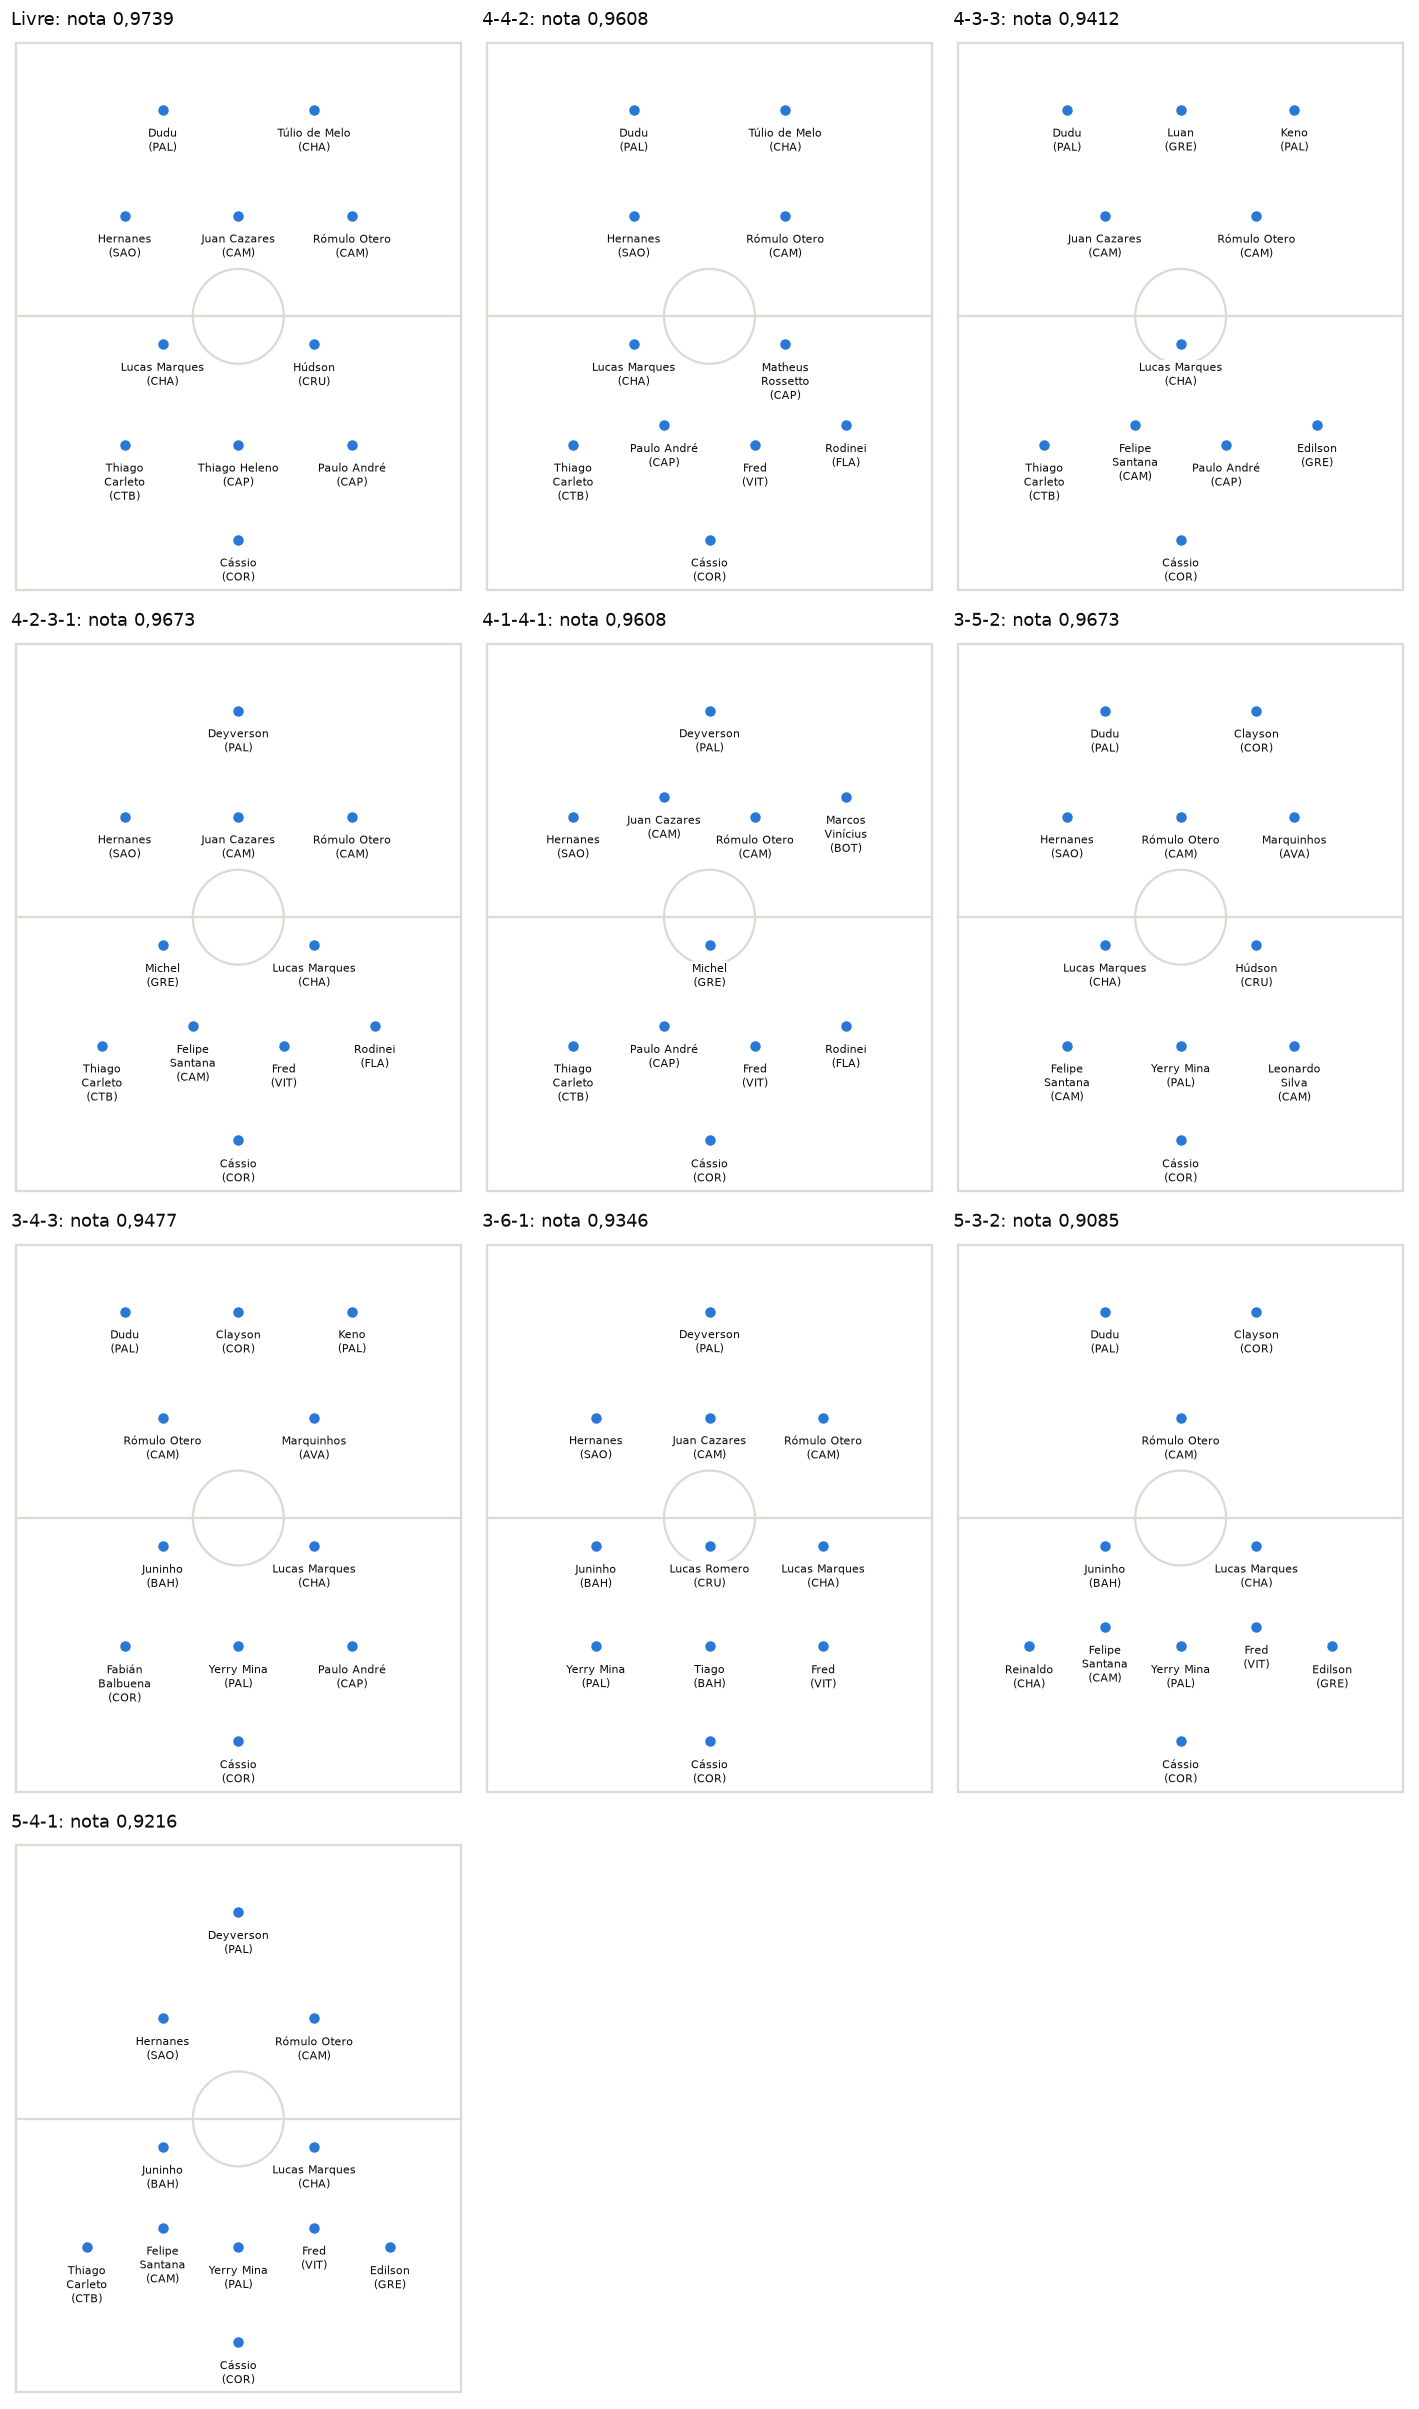

In [5]:
ROWS = [("ATA",), ("MEI",), ("VOL",), ("LE", "ZAG", "LD")]
HEIGHTS = [0.87, 0.68, 0.45, 0.27]


def label(name):
    player, club = name.rsplit(" (", 1)
    return f"{fill(player, 13)}\n({club}"


def draw_pitch(axes, team, title):
    axes.set_xlim(0, 1)
    axes.set_ylim(0, 1)
    axes.axis("off")
    axes.add_patch(plt.Rectangle((0.01, 0.01), 0.98, 0.98, fill=False, edgecolor=LINE, linewidth=1.5))
    axes.plot([0.01, 0.99], [0.5, 0.5], color=LINE, linewidth=1.5, zorder=0)
    axes.add_patch(Ellipse((0.5, 0.5), 0.2, 0.17, fill=False, edgecolor=LINE, linewidth=1.5))
    axes.set_title(title, fontsize=12, pad=8)

    for row, height in zip(ROWS, HEIGHTS):
        players = sorted(
            (player for player in team if dataset.positions[player] in row),
            key=lambda player: (row.index(dataset.positions[player]), -strengths[player]),
        )
        for index, player in enumerate(players):
            x = (index + 1) / (len(players) + 1)
            y = height + (0.035 if len(players) > 3 and index % 2 else 0)
            draw_player(axes, x, y, dataset.players[player])
    draw_player(axes, 0.5, 0.1, dataset.goalkeeper["name"])


def draw_player(axes, x, y, name):
    axes.scatter([x], [y], s=70, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
    axes.text(x, y - 0.03, label(name), ha="center", va="top", fontsize=7.5, color=INK, zorder=4,
              bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.8})


figure, grid = plt.subplots(4, 3, figsize=(13, 22))
for axes in grid.flat:
    axes.axis("off")
for axes, (name, result) in zip(grid.flat, results.items()):
    score = f"{result.score:.4f}".replace(".", ",")
    draw_pitch(axes, result.team, f"{name}: nota {score}")
figure.tight_layout()
figure.savefig("images/times.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()

O time livre tem a maior nota, com 149 de 153 pares, porque não precisa cumprir quotas. O 4-2-3-1 e o 3-5-2 ficam um par atrás, e o 5-3-2 fecha a lista, com 139 pares.

## Complementar não é somar os melhores

Aqui, o time livre é comparado com os 10 jogadores de maior desempenho somado nos 18 critérios, sem o peso da posição. O gráfico mostra o desempenho médio de cada time em cada critério, a mesma média que entra na nota.

In [6]:
strongest = np.argsort(-strengths, kind="stable")[:10].tolist()
complementary = list(results["Livre"].team)
strongest_score = scorer.rate(strongest)[0]

print(f"10 jogadores de maior desempenho somado: nota {strongest_score:.4f} ({round(strongest_score * 153)} de 153 pares)")
print(f"Time mais complementar:                  nota {results['Livre'].score:.4f} ({round(results['Livre'].score * 153)} de 153 pares)")
print(f"Jogadores em comum: {len(set(strongest) & set(complementary))} de 10")
print("Só nos mais fortes:", ", ".join(dataset.players[p] for p in strongest if p not in complementary))
print("Só no complementar:", ", ".join(dataset.players[p] for p in complementary if p not in strongest))

10 jogadores de maior desempenho somado: nota 0.6863 (105 de 153 pares)
Time mais complementar:                  nota 0.9739 (149 de 153 pares)
Jogadores em comum: 4 de 10
Só nos mais fortes: Gustavo Scarpa (FLU), Marcos Rocha (CAM), Thiago Neves (CRU), Lucas Lima (SAN), Luan (GRE), Felipe Santana (CAM)
Só no complementar: Túlio de Melo (CHA), Rómulo Otero (CAM), Húdson (CRU), Lucas Marques (CHA), Paulo André (CAP), Thiago Heleno (CAP)


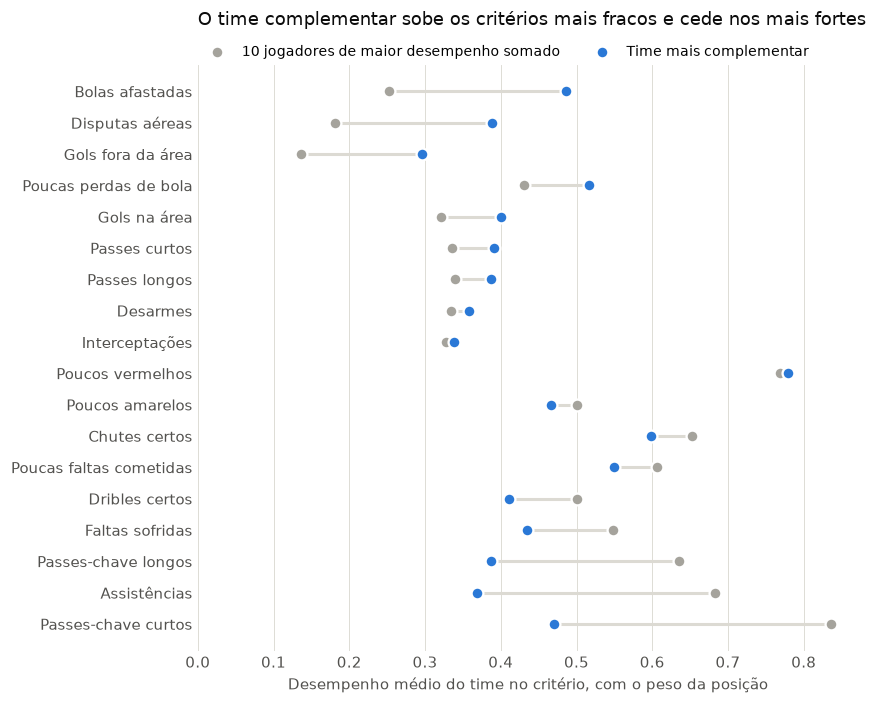

In [7]:
NAMES = {
    "Tackles": "Desarmes", "Interception": "Interceptações", "Fouled": "Faltas sofridas",
    "Fouls": "Poucas faltas cometidas", "Yellow": "Poucos amarelos", "Red": "Poucos vermelhos",
    "Clearences": "Bolas afastadas", "ShotsW": "Chutes certos", "GolsA": "Gols na área",
    "GolsFA": "Gols fora da área", "DribblesSuccessful": "Dribles certos",
    "PossLost": "Poucas perdas de bola", "AerialWon": "Disputas aéreas", "AccLB": "Passes longos",
    "AccSP": "Passes curtos", "KPLong": "Passes-chave longos", "KPShort": "Passes-chave curtos",
    "AssistsTotal": "Assistências",
}
weak = scorer.payment[strongest].mean(axis=0)
strong = scorer.payment[complementary].mean(axis=0)
order = np.argsort(strong - weak, kind="stable")
y = np.arange(len(order))

figure, axes = plt.subplots(figsize=(8, 6.5))
axes.hlines(y, weak[order], strong[order], color=LINE, linewidth=2, zorder=1)
axes.scatter(weak[order], y, s=60, color=GRAY, edgecolor="white", linewidth=1.5, zorder=2,
             label="10 jogadores de maior desempenho somado")
axes.scatter(strong[order], y, s=60, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3,
             label="Time mais complementar")
axes.set_yticks(y, [NAMES[dataset.criteria[i]] for i in order])
axes.set_xlim(0, None)
axes.set_xlabel("Desempenho médio do time no critério, com o peso da posição")
axes.set_title("O time complementar sobe os critérios mais fracos e cede nos mais fortes", pad=26)
axes.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, frameon=False, borderaxespad=0, fontsize=9)
axes.grid(axis="x", color=LINE, linewidth=0.6)
axes.set_axisbelow(True)
axes.tick_params(length=0)
axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
figure.tight_layout()
figure.savefig("images/cobertura.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()

Os dois times têm 4 jogadores em comum. Saem Scarpa, Marcos Rocha, Thiago Neves, Lucas Lima, Luan e Felipe Santana, e entram Túlio de Melo, Rómulo Otero, Húdson, Lucas Marques, Paulo André e Thiago Heleno. O time perde em passes-chave e assistências, mas sobe nos critérios em que os mais fortes são fracos: gols fora da área vão de 0,14 para 0,30, disputas aéreas, de 0,18 para 0,39, e bolas afastadas, de 0,25 para 0,49. Como o par vale pelo critério mais fraco, isso pesa muito: nos mais fortes, todo par com gols fora da área ou com disputas aéreas fica abaixo do tau. Os pares que passam sobem de 105 para 149, e a nota, de 0,6863 para 0,9739.

## Como o algoritmo chega lá

O gráfico mostra a melhor nota encontrada a cada iteração, com a execução da semente 0 no 4-4-2. O eixo das iterações está em escala logarítmica, porque quase tudo acontece no começo.

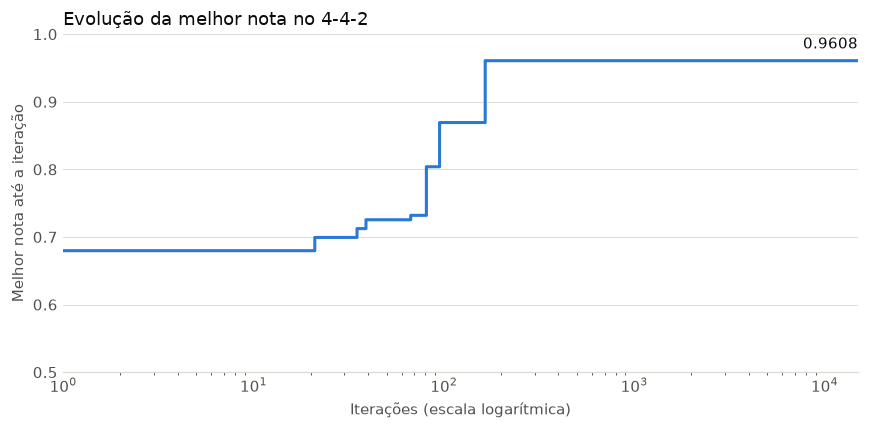

In [8]:
history = results["4-4-2"].history
iterations = np.arange(1, len(history) + 1)

figure, axes = plt.subplots(figsize=(8, 4))
axes.step(iterations, history, where="post", color=BLUE, linewidth=2)
axes.annotate(f"{history[-1]:.4f}", (iterations[-1], history[-1]), xytext=(0, 8),
              textcoords="offset points", ha="right", color=INK)
axes.set_title("Evolução da melhor nota no 4-4-2")
axes.set_xlabel("Iterações (escala logarítmica)")
axes.set_ylabel("Melhor nota até a iteração")
axes.set_xscale("log")
axes.set_xlim(1, len(history))
axes.set_ylim(0.5, 1)
axes.grid(axis="y", color=LINE, linewidth=0.6)
axes.set_axisbelow(True)
axes.tick_params(length=0)
axes.spines[["top", "right", "left"]].set_visible(False)
figure.tight_layout()
plt.show()

A melhor nota já começa em 0,6797, porque times sorteados passam em parte dos pares. Nesta execução, a busca chega a 0,9608 na iteração 165, e a nota não muda depois disso. Outras formações demoram mais: com a mesma semente, o 4-3-3 e o 3-5-2 só chegaram à melhor nota depois da iteração 3.500.

## Quem aparece em todas as formações

Os jogadores que se repetem são os que continuam úteis quando a estrutura do time muda.

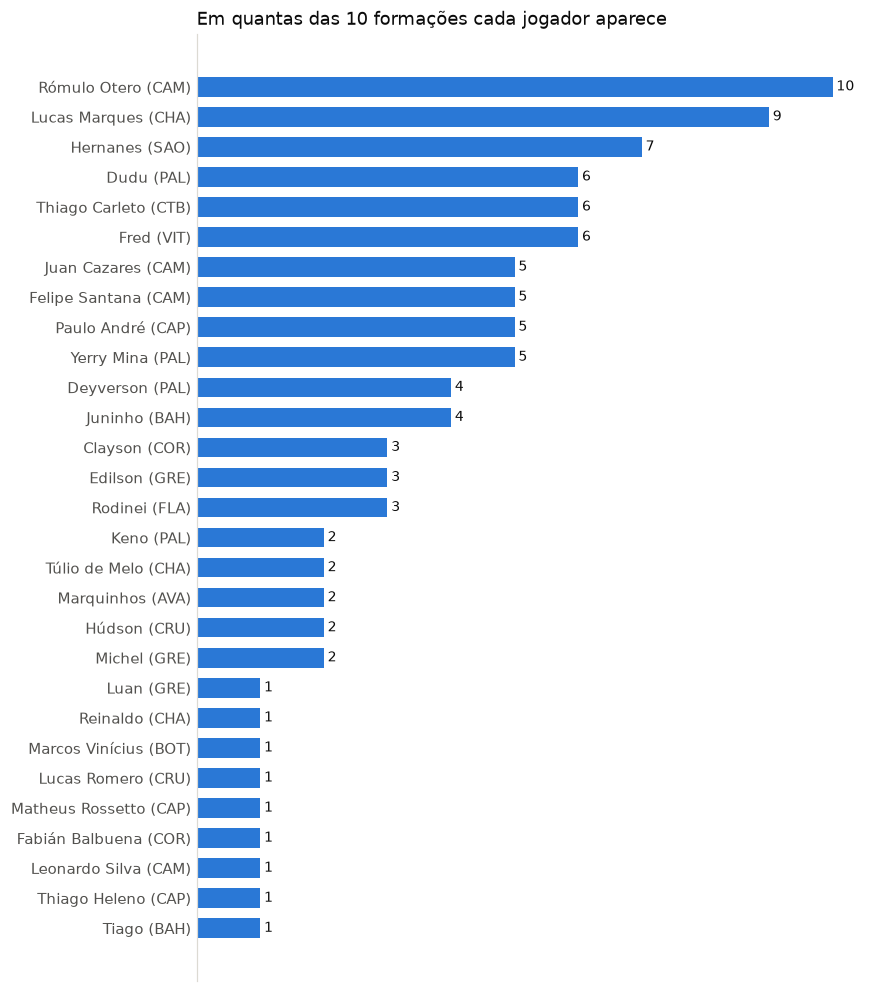

In [9]:
presence = Counter(player for result in results.values() for player in result.team)
ranking = sorted(presence.items(), key=lambda item: (item[1], -item[0]))
names = [dataset.players[player] for player, _ in ranking]
counts = [count for _, count in ranking]

figure, axes = plt.subplots(figsize=(8, 0.28 * len(names) + 1))
axes.barh(names, counts, color=BLUE, height=0.65)
for index, count in enumerate(counts):
    axes.text(count + 0.06, index, str(count), va="center", color=INK, fontsize=9)
axes.set_xlim(0, len(results) + 0.4)
axes.set_xticks([])
axes.set_title(f"Em quantas das {len(results)} formações cada jogador aparece")
axes.tick_params(length=0)
axes.spines[["top", "right", "bottom"]].set_visible(False)
figure.tight_layout()
plt.show()

Rómulo Otero aparece nas 10 formações, Lucas Marques em 9 e Hernanes em 7. Dos 29 jogadores que entram em algum time, 9 aparecem uma vez só.

## O goleiro

O goleiro não entra nos pares de critérios, porque suas estatísticas são outras. Ele é escolhido por três critérios: aproveitamento de defesas, acerto de passes longos e bolas afastadas por 90 minutos. Atingir um critério é ficar entre os 20% melhores, e o desempate é o aproveitamento de defesas.

In [10]:
from comum.goleiros import rank_goalkeepers

print(f"{'Goleiro':26s} {'Critérios':>9s} {'Defesas':>9s} {'Passe longo':>12s} {'Afastadas/90':>13s}")
for keeper in rank_goalkeepers()[:5]:
    print(f"{keeper['name']:26s} {keeper['hits']:>9d} {keeper['save_rate']:>9.1%} "
          f"{keeper['long_pass_rate']:>12.1%} {keeper['clearances_per_90']:>13.2f}")

Goleiro                    Critérios   Defesas  Passe longo  Afastadas/90
Cássio (COR)                       2     78.4%        48.0%          0.57
Marcos (ACG)                       2     77.2%        49.4%          1.45
Vanderlei (SAN)                    1     80.8%        40.7%          1.27
Marcelo Grohe (GRE)                1     78.5%        34.0%          0.96
Douglas Friedrich (AVA)            1     77.0%        38.8%          1.36
